# Phase 2 — Exploratory Data Analysis: FD002
**Notebook:** `05_EDA_FD002.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

FD002 = **260 training engines, 259 test engines, 6 operating conditions, 1 fault mode (HPC degradation)**.
Compared with FD001, the big new challenge is the **six operating conditions (regimes)**: the aircraft flies at different altitudes / Mach numbers / throttle settings, and each condition shifts every sensor's normal value. A model that ignores this will confuse "flying in a different condition" with "the engine is wearing out".

This notebook follows the same 10 EDA steps as FD001, plus a dedicated **operating-regime analysis**. EDA only *reads and plots* — every decision (which sensors to drop, how to normalise) is proposed here and made in Phase 3.



## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD002", 42
FIG_DIR = PROJECT_DIR / "reports" / "figures" / FD
TAB_DIR = PROJECT_DIR / "reports" / "eda" / FD
for p in (FIG_DIR, TAB_DIR):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

import src.data_loader as dl
importlib.reload(dl)
SETTINGS, SENSORS = dl.SETTING_COLS, dl.SENSOR_COLS
print("Ready")

Mounted at /content/drive
Ready


## Cell 2 — Load FD002 (read-only) and add an EDA-only RUL column
Same loader as FD001 (`src/data_loader.py`). The RUL column is added to a **copy** for exploration; Phase 3 creates the official labels.

In [2]:
# Cell 2 — Load
d = dl.load_dataset(FD, RAW_DIR)
train, test, rul = d["train"], d["test"], d["rul"]
eda = train.copy()
eda["RUL"] = eda.groupby("engine_id")["cycle"].transform("max") - eda["cycle"]

print(f"train {train.shape} | {train.engine_id.nunique()} engines")
print(f"test  {test.shape} | {test.engine_id.nunique()} engines | RUL file {len(rul)} rows")
print("Missing values:", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))

train (53759, 26) | 260 engines
test  (33991, 26) | 259 engines | RUL file 259 rows
Missing values: 0 / 0


**Expected:** train `(53759, 26)` with 260 engines; test `(33991, 26)` with 259 engines; 259 RUL rows; 0 missing values.

---
## 2.1 — Engine lifetime distribution

Train lifetimes:
count    260.0
mean     206.8
std       46.8
min      128.0
25%      174.0
50%      199.0
75%      230.2
max      378.0
Name: cycle, dtype: float64
Skewness: 0.99

Test observed lengths:
count    259.0
mean     131.2
std       63.1
min       21.0
25%       76.5
50%      132.0
75%      168.0
max      367.0
Name: cycle, dtype: float64
Test engines with fewer than 25 cycles: 3
Test engines with fewer than 30 cycles: 6
Test engines with fewer than 40 cycles: 12


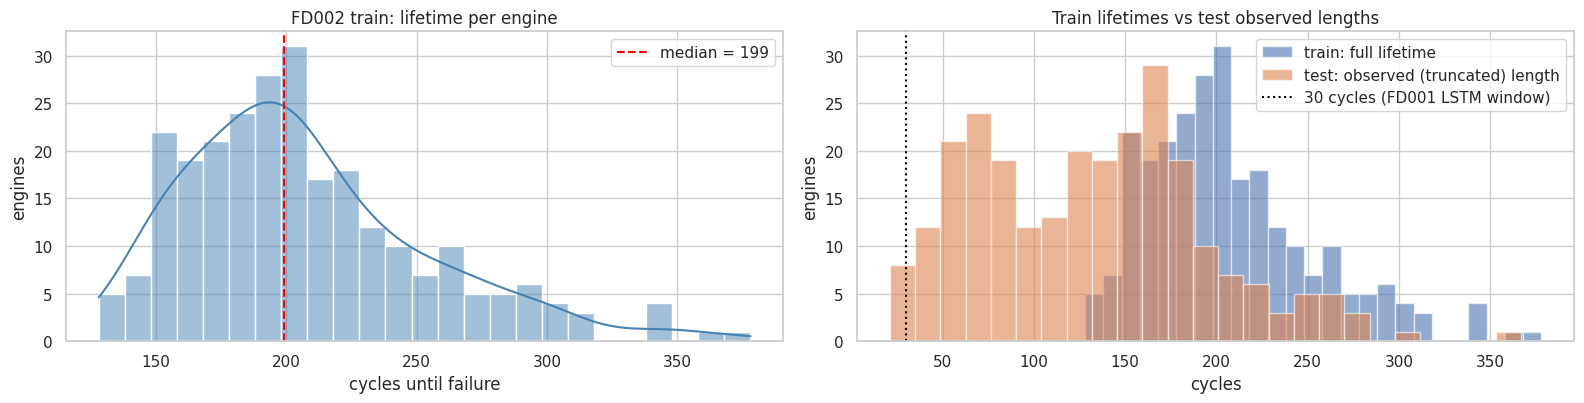

In [3]:
# Cell 3 — Lifetimes (train) vs observed lengths (test)
train_life = train.groupby("engine_id")["cycle"].max()
test_obs   = test.groupby("engine_id")["cycle"].max()
print("Train lifetimes:"); print(train_life.describe().round(1)); print("Skewness:", round(train_life.skew(), 2))
print("\nTest observed lengths:"); print(test_obs.describe().round(1))
for k in (25, 30, 40):
    print(f"Test engines with fewer than {k} cycles: {(test_obs < k).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
sns.histplot(train_life, bins=25, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(train_life.median(), color="red", ls="--", label=f"median = {train_life.median():.0f}")
axes[0].set(title="FD002 train: lifetime per engine", xlabel="cycles until failure", ylabel="engines"); axes[0].legend()
axes[1].hist(train_life, bins=25, alpha=0.6, label="train: full lifetime")
axes[1].hist(test_obs, bins=25, alpha=0.6, label="test: observed (truncated) length")
axes[1].axvline(30, color="black", ls=":", label="30 cycles (FD001 LSTM window)")
axes[1].set(title="Train lifetimes vs test observed lengths", xlabel="cycles", ylabel="engines"); axes[1].legend()
fig.tight_layout(); save_fig(fig, "01_engine_lifetime_distribution"); plt.show()

**Interpretation (actual FD002 values):**
- Lifetimes range **128–378 cycles** (median **199**, mean 206.8, skew ≈ 0.99) — almost identical to FD001's 128–362 / 199. Same engine type, same fault, so similar life spans make sense.
- Test histories are much shorter (median 132) and as short as **21 cycles**. **6 test engines have fewer than 30 cycles** (3 have fewer than 25).

**Implication — important for the LSTM:** in FD001 we used 30-cycle sequences because the shortest test engine had 31 cycles. For FD002 a 30-cycle window would make 6 test engines unpredictable. Phase 3/4 must choose a shorter window (≤ 21) or a documented padding strategy. The rolling-feature models are unaffected (`min_periods=1`).

## 2.2 — Operating cycle coverage

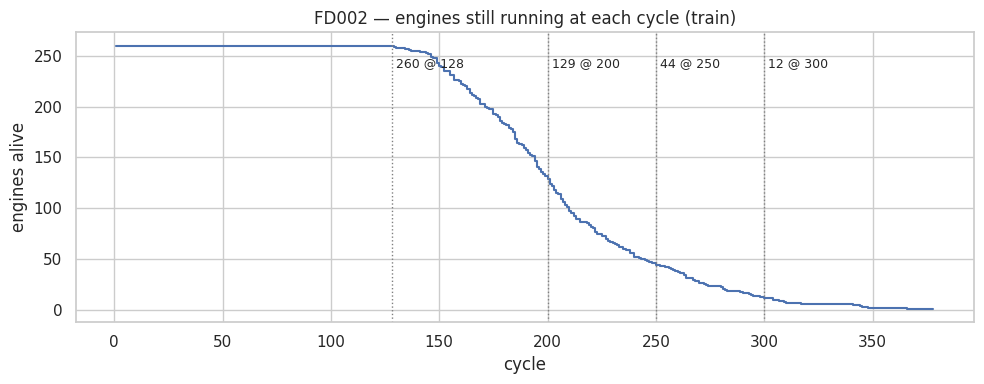

Engines alive at cycle 128 / 200 / 250 / 300: [260, 129, 44, 12]


In [4]:
# Cell 4 — Engines still running at each cycle
alive = pd.Series([(train_life >= t).sum() for t in range(1, train_life.max() + 1)],
                  index=range(1, train_life.max() + 1))
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(alive.index, alive.values, where="post")
for q in (128, 200, 250, 300):
    ax.axvline(q, color="grey", ls=":", lw=1); ax.text(q, alive.max() * 0.92, f" {alive.get(q, 0)} @ {q}", fontsize=9)
ax.set(title="FD002 — engines still running at each cycle (train)", xlabel="cycle", ylabel="engines alive")
fig.tight_layout(); save_fig(fig, "02_cycle_coverage"); plt.show()
print("Engines alive at cycle 128 / 200 / 250 / 300:", [int(alive.get(c, 0)) for c in (128, 200, 250, 300)])

**Interpretation:** same shape as FD001 — all 260 engines run to at least cycle 128, then the count drops. With 2.6× more engines than FD001, the late-life region has more examples, which should help the models there.

---
## 2.3 — Operating settings & regime discovery (new for FD002)
The three operational settings are altitude-, Mach- and throttle-related values. If they cluster into a few discrete combinations, each combination is one **operating regime**.

**Method:** round the settings to a coarse grid (`op_setting_1` → whole number, `op_setting_2` → 2 decimals, `op_setting_3` → whole number) and count distinct combinations. We cross-check with K-Means clustering — if both agree, the regimes are real and unambiguous.

,regime,op_setting_1,op_setting_2,op_setting_3,train_rows,share,test_rows
0,1,0.0,0.00,100.0,8044,0.150,5148
1,2,10.0,0.25,100.0,8096,0.151,5107
2,3,20.0,0.70,100.0,8122,0.151,5063
3,4,25.0,0.62,60.0,8002,0.149,5042
4,5,35.0,0.84,100.0,8037,0.150,5148
5,6,42.0,0.84,100.0,13458,0.250,8483


Test rows in an unknown regime: 0
K-Means vs rounding: every K-Means cluster maps to exactly one regime → True
Average share of cycles where the regime changes from the previous cycle: 82.1%


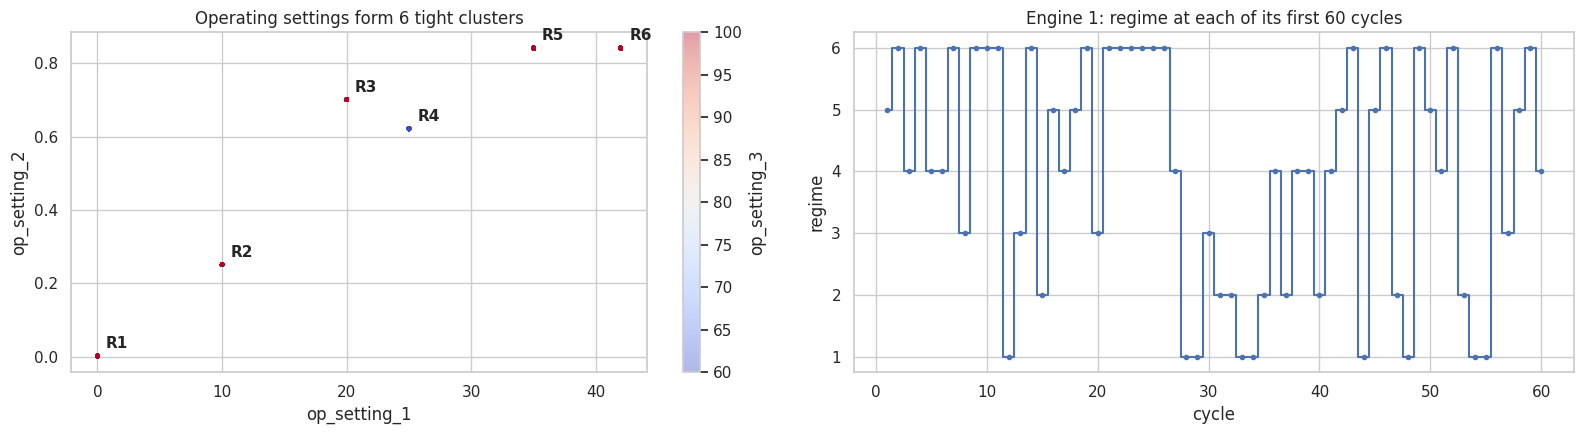

In [5]:
# Cell 5 — Discover regimes
ROUND = {"op_setting_1": 0, "op_setting_2": 2, "op_setting_3": 0}
regime_table = (train[SETTINGS].round(ROUND).drop_duplicates()
                .sort_values(SETTINGS).reset_index(drop=True))
regime_table.insert(0, "regime", np.arange(1, len(regime_table) + 1))
lookup = {tuple(r[SETTINGS]): int(r.regime) for _, r in regime_table.iterrows()}

def assign_regime(df):
    keys = map(tuple, df[SETTINGS].round(ROUND).values)
    return pd.Series([lookup.get(k, -1) for k in keys], index=df.index, name="regime")

eda["regime"] = assign_regime(eda)
test_regime = assign_regime(test)
regime_table["train_rows"] = eda.regime.value_counts().reindex(regime_table.regime).values
regime_table["share"] = (regime_table.train_rows / len(eda)).round(3)
regime_table["test_rows"] = test_regime.value_counts().reindex(regime_table.regime).fillna(0).astype(int).values
display(regime_table)
print("Test rows in an unknown regime:", int((test_regime == -1).sum()))

from sklearn.cluster import KMeans
km = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit(train[SETTINGS])
agree = pd.crosstab(km.labels_, eda.regime)
print("K-Means vs rounding: every K-Means cluster maps to exactly one regime →",
      bool(((agree > 0).sum(axis=1) == 1).all()))

switch_rate = eda.groupby("engine_id").regime.apply(lambda s: (s.diff().fillna(0) != 0).mean()).mean()
print(f"Average share of cycles where the regime changes from the previous cycle: {switch_rate:.1%}")
regime_table.to_csv(TAB_DIR / "regime_table.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sc = axes[0].scatter(train.op_setting_1, train.op_setting_2, c=train.op_setting_3, cmap="coolwarm", s=4, alpha=0.4)
for _, r in regime_table.iterrows():
    axes[0].annotate(f"R{int(r.regime)}", (r.op_setting_1, r.op_setting_2), fontsize=11, weight="bold",
                     xytext=(6, 6), textcoords="offset points")
axes[0].set(title="Operating settings form 6 tight clusters", xlabel="op_setting_1", ylabel="op_setting_2")
fig.colorbar(sc, ax=axes[0], label="op_setting_3")
e1 = eda[eda.engine_id == eda.engine_id.min()].head(60)
axes[1].step(e1.cycle, e1.regime, where="mid", marker="o", ms=3)
axes[1].set(title=f"Engine {e1.engine_id.iloc[0]}: regime at each of its first 60 cycles",
            xlabel="cycle", ylabel="regime", yticks=range(1, 7))
fig.tight_layout(); save_fig(fig, "03_operating_regimes"); plt.show()

**Interpretation (actual values):**
- Exactly **6 regimes**, and K-Means finds the same 6 groups → the conditions are discrete and unambiguous. Within a regime, the settings only show tiny measurement noise.
- One regime (**op_setting_1 ≈ 42, op_setting_2 ≈ 0.84**) holds **25%** of rows; the other five ≈ **15%** each. Only one regime uses `op_setting_3 = 60`; the rest use 100.
- Every test row falls into one of the 6 training regimes → no unseen conditions.
- The regime changes on **~82% of cycles** — i.e. it is essentially re-drawn at random every flight. So the regime carries **no information about wear**; it's a nuisance factor we must remove, not a signal.

## 2.4 — Sensor statistical summary (raw)

In [6]:
# Cell 6 — Raw descriptive statistics
summary = train[SENSORS].describe().T
summary["n_unique"] = train[SENSORS].nunique()
summary.to_csv(TAB_DIR / "feature_summary_raw.csv")
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,n_unique
sensor_1,53759.0,472.910,26.390,445.000,445.000,462.540,491.190,518.670,6
sensor_2,53759.0,579.672,37.289,535.530,549.570,555.980,607.340,644.520,1590
sensor_3,53759.0,1419.971,105.946,1243.730,1352.760,1369.180,1499.370,1612.880,12305
sensor_4,53759.0,1205.442,119.123,1023.770,1123.655,1138.890,1306.850,1439.230,15411
sensor_5,53759.0,8.032,3.614,3.910,3.910,7.050,10.520,14.620,6
sensor_6,53759.0,11.601,5.432,5.710,5.720,9.030,15.490,21.610,14
sensor_7,53759.0,282.607,146.005,136.800,139.935,194.660,394.080,555.820,2067
sensor_8,53759.0,2228.879,145.210,1914.770,2211.880,2223.070,2323.960,2388.390,897
sensor_9,53759.0,8525.201,335.812,7985.560,8321.660,8361.200,8778.030,9215.660,22434
sensor_10,53759.0,1.095,0.127,0.930,1.020,1.020,1.260,1.300,9


**What to notice:** the raw standard deviations are far larger than in FD001 (e.g. `sensor_9` std is ~22 in FD001 but ~336 here). That extra spread is **regime shifts**, not degradation — the next cells prove it.

## 2.5 — Sensor distributions (coloured by regime)

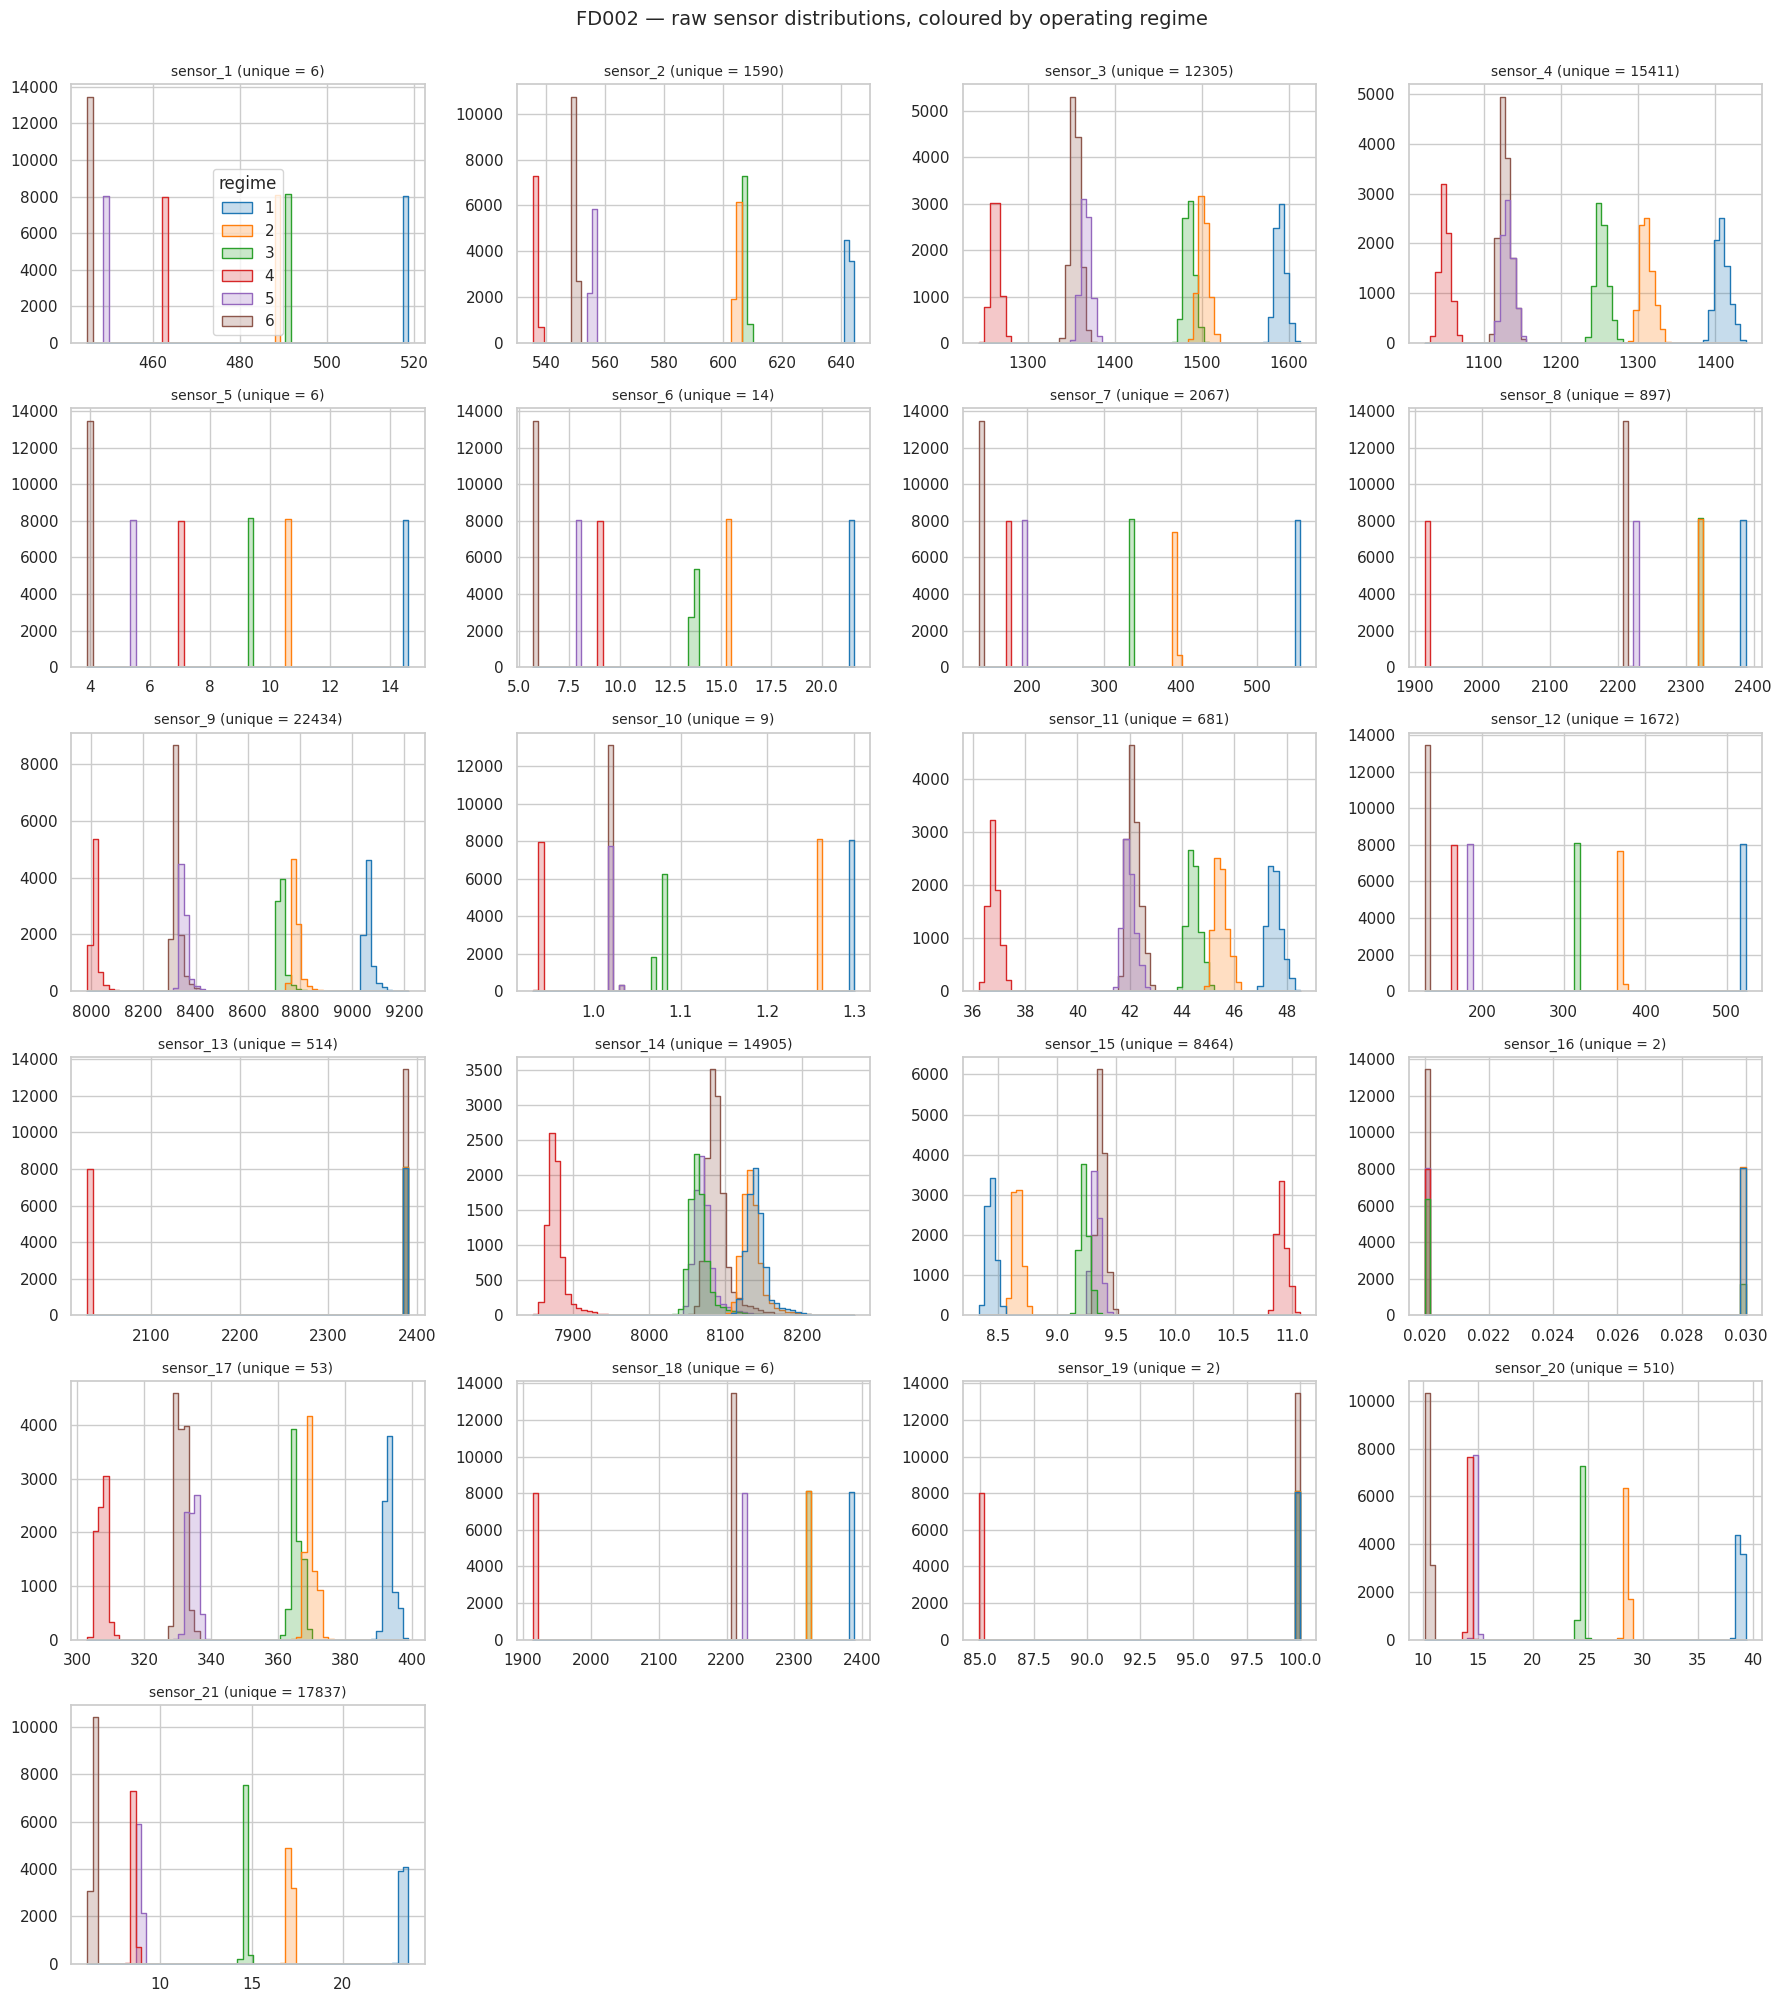

In [7]:
# Cell 7 — Histograms, coloured by regime
fig, axes = plt.subplots(6, 4, figsize=(18, 20))
for i, (ax, col) in enumerate(zip(axes.flat, SENSORS)):
    sns.histplot(eda, x=col, hue="regime", bins=60, element="step", stat="count", palette="tab10",
                 ax=ax, legend=(i == 0))
    ax.set_title(f"{col} (unique = {train[col].nunique()})", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(SENSORS):]:
    ax.axis("off")
fig.suptitle("FD002 — raw sensor distributions, coloured by operating regime", y=1.0, fontsize=14)
fig.tight_layout(); save_fig(fig, "04_sensor_distributions_by_regime"); plt.show()

**Interpretation:** almost every sensor shows **several separate peaks — one per regime**. Each coloured hump is a clean bell shape, but the humps sit far apart. That means:
1. A single global scaler (as in FD001) would mostly measure the distance *between* regimes, drowning the small degradation signal *within* a regime.
2. Some sensors (`sensor_1`, `sensor_5`, `sensor_18`, `sensor_19`) have **one fixed value per regime** — their 6 raw "unique values" are just the 6 regimes.

## 2.6 — Variance analysis: within-regime vs raw
In FD001 we flagged constant sensors by counting distinct values. In FD002 that's misleading: `sensor_1` has 6 distinct values, but only because of the 6 regimes. The right question is: **does the sensor vary *within* a regime?**

In [8]:
# Cell 8 — Within-regime variability
g = eda.groupby("regime")[SENSORS]
var_df = pd.DataFrame({
    "raw_n_unique": train[SENSORS].nunique(),
    "max_n_unique_within_regime": g.nunique().max(),
    "max_std_within_regime": g.std().max(),
    "variance_explained_by_regime_%": (1 - g.var().mean() / train[SENSORS].var().replace(0, np.nan)) * 100,
})
var_df["flag"] = np.select(
    [var_df.max_n_unique_within_regime == 1, var_df.max_n_unique_within_regime <= 3],
    ["CONSTANT WITHIN REGIME", "QUANTISED (≤3 values per regime)"], default="variable")
var_df.to_csv(TAB_DIR / "variance_report.csv")
display(var_df.round(4))
for f in ["CONSTANT WITHIN REGIME", "QUANTISED (≤3 values per regime)"]:
    print(f"{f}: {var_df.index[var_df.flag == f].tolist()}")
print("variable:", var_df.index[var_df.flag == "variable"].tolist())

,raw_n_unique,max_n_unique_within_regime,max_std_within_regime,variance_explained_by_regime_%,flag
sensor_1,6,1,0.0000,100.0000,CONSTANT WITHIN REGIME
sensor_2,1590,288,0.4959,99.9857,variable
sensor_3,12305,2596,6.0224,99.7114,variable
sensor_4,15411,3280,8.9368,99.5635,variable
sensor_5,6,1,0.0000,100.0000,CONSTANT WITHIN REGIME
sensor_6,14,3,0.0049,99.9999,QUANTISED (≤3 values per regime)
sensor_7,2067,464,0.8680,99.9983,variable
sensor_8,897,257,0.2997,99.9998,variable
sensor_9,22434,4890,19.2126,99.7324,variable
sensor_10,9,2,0.0042,99.9749,QUANTISED (≤3 values per regime)


CONSTANT WITHIN REGIME: ['sensor_1', 'sensor_5', 'sensor_18', 'sensor_19']
QUANTISED (≤3 values per regime): ['sensor_6', 'sensor_10', 'sensor_16']
variable: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


**Interpretation (actual values):**
- **Constant within every regime:** `sensor_1`, `sensor_5`, `sensor_18`, `sensor_19` → after removing the regime they carry **zero** information. Same four (plus others) were constant in FD001.
- **Quantised:** `sensor_6`, `sensor_10`, `sensor_16` take only 1–3 values inside a regime (recorded at coarse resolution). Not automatically useless — see the drill-down below.
- **Variable:** the same **14 sensors** that carried the degradation signal in FD001 (2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21).
- For the key sensors, the regime explains **96.7–99.99%** of total variance (`sensor_2` 99.99%, `sensor_11` 99.45%, lowest `sensor_14` 96.7%). Degradation lives in the remaining < 1%.

In [9]:
# Cell 8b — Drill-down: do the quantised sensors' values relate to wear?
quant = var_df.index[var_df.flag.str.startswith("QUANTISED")].tolist()
for c in quant:
    t = eda.groupby(["regime", c]).agg(rows=("RUL", "size"), mean_RUL=("RUL", "mean")).round(1)
    print(f"\n{c}: mean RUL for each value, per regime"); display(t)


sensor_6: mean RUL for each value, per regime


rows  mean_RUL
regime sensor_6                
1      21.60      136     178.0
       21.61     7908     106.9
2      15.49     5436     137.6
       15.50     2660      49.1
3      13.65     2745     156.7
       13.66     5375      83.6
       13.67        2       1.5
4      9.02      1796     147.3
       9.03      6202      95.7
       9.04         4       1.5
5      8.00      7799     110.4
       8.01       238      13.8
6      5.71      5599     131.3
       5.72      7859      92.9


sensor_10: mean RUL for each value, per regime


rows  mean_RUL
regime sensor_10                 
1      1.30        8044     108.1
2      1.25           3       5.3
       1.26        8093     108.5
3      1.07        1843      60.2
       1.08        6279     122.4
4      0.93          63      63.3
       0.94        7939     107.6
5      1.02        7723     106.0
       1.03         314     144.1
6      1.02       13129     110.9
       1.03         329      25.2


sensor_16: mean RUL for each value, per regime


rows  mean_RUL
regime sensor_16                 
1      0.03        8044     108.1
2      0.03        8096     108.5
3      0.02        6382     128.3
       0.03        1740      34.8
4      0.02        8002     107.2
5      0.02        8037     107.5
6      0.02       13458     108.8

**Interpretation:**
- `sensor_6`: in every regime the **higher** value has a clearly lower mean RUL (e.g. ~49 vs ~138 in one regime) → it behaves like a coarse wear flag. Potentially useful.
- `sensor_16`: changes value **only in one regime** (from 0.02 to 0.03 near failure, mean RUL ≈ 35 vs 128); constant in the other five. Informative but only for ~15% of cycles.
- `sensor_10`: mixed — in some regimes the rarer value is near failure, in others far from it; and the rare values cover very few rows. Weak/unreliable.

➡️ **Phase 3 decision needed:** the FD001 rule ("drop if < 3 distinct values") must be applied **within regimes**, and we should test on validation whether keeping `sensor_6` / `sensor_16` helps — rather than assuming.

---
## 2.7 — Regime normalisation (what Phase 3 will formalise)
**Idea:** standardise each sensor **separately within each regime**:
`z = (value − mean of that sensor in that regime) / (std of that sensor in that regime)`.
After this, a reading of `z = +2` means "2 standard deviations above normal *for the condition it was flying in*" — comparable across regimes.

⚠️ EDA-only: here the regime means/stds are computed on all 260 training engines just to *look*. In Phase 3 they will be fitted on the training split only (no leakage).

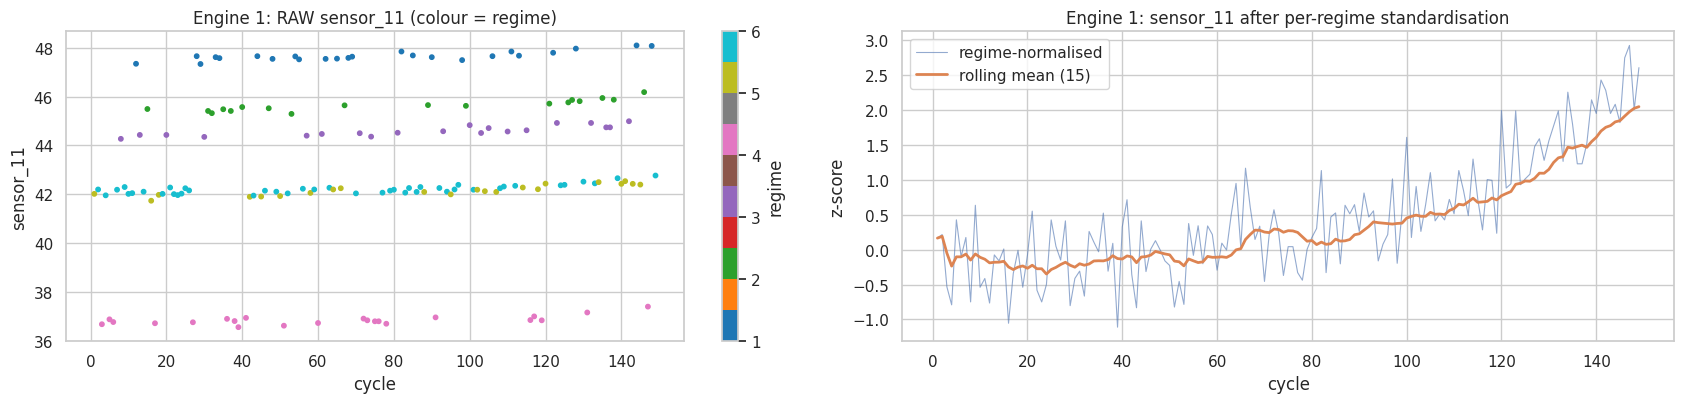

In [10]:
# Cell 9 — Per-regime z-scores (EDA only) and the effect on one engine
gstats = eda.groupby("regime")[SENSORS]
mu, sd = gstats.transform("mean"), gstats.transform("std").replace(0, np.nan)
z = eda[["engine_id", "cycle", "RUL", "regime"]].join((eda[SENSORS] - mu) / sd)

eid = eda.engine_id.min()
e_raw, e_z = eda[eda.engine_id == eid], z[z.engine_id == eid]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
sc = axes[0].scatter(e_raw.cycle, e_raw.sensor_11, c=e_raw.regime, cmap="tab10", s=10)
axes[0].set(title=f"Engine {eid}: RAW sensor_11 (colour = regime)", xlabel="cycle", ylabel="sensor_11")
fig.colorbar(sc, ax=axes[0], label="regime")
axes[1].plot(e_z.cycle, e_z.sensor_11, lw=0.8, alpha=0.6, label="regime-normalised")
axes[1].plot(e_z.cycle, e_z.sensor_11.rolling(15, min_periods=1).mean(), lw=2, label="rolling mean (15)")
axes[1].set(title=f"Engine {eid}: sensor_11 after per-regime standardisation", xlabel="cycle", ylabel="z-score")
axes[1].legend()
fig.tight_layout(); save_fig(fig, "05_regime_normalisation_example"); plt.show()

**Interpretation:** the raw signal (left) is six horizontal bands — the engine jumping between conditions — and the wear trend is invisible. After per-regime standardisation (right) the bands collapse onto one line and the familiar **upward degradation trend** appears, accelerating near the end of life — exactly like FD001.

## 2.8 — Correlation with RUL: raw vs regime-normalised

,raw,regime_normalised
sensor_11,-0.047,-0.694
sensor_4,-0.041,-0.662
sensor_15,-0.038,-0.650
sensor_17,-0.027,-0.579
sensor_2,-0.005,-0.567
sensor_3,-0.027,-0.555
sensor_16,-0.071,-0.551
sensor_13,0.005,-0.413
sensor_8,0.004,-0.412
sensor_9,-0.015,-0.355


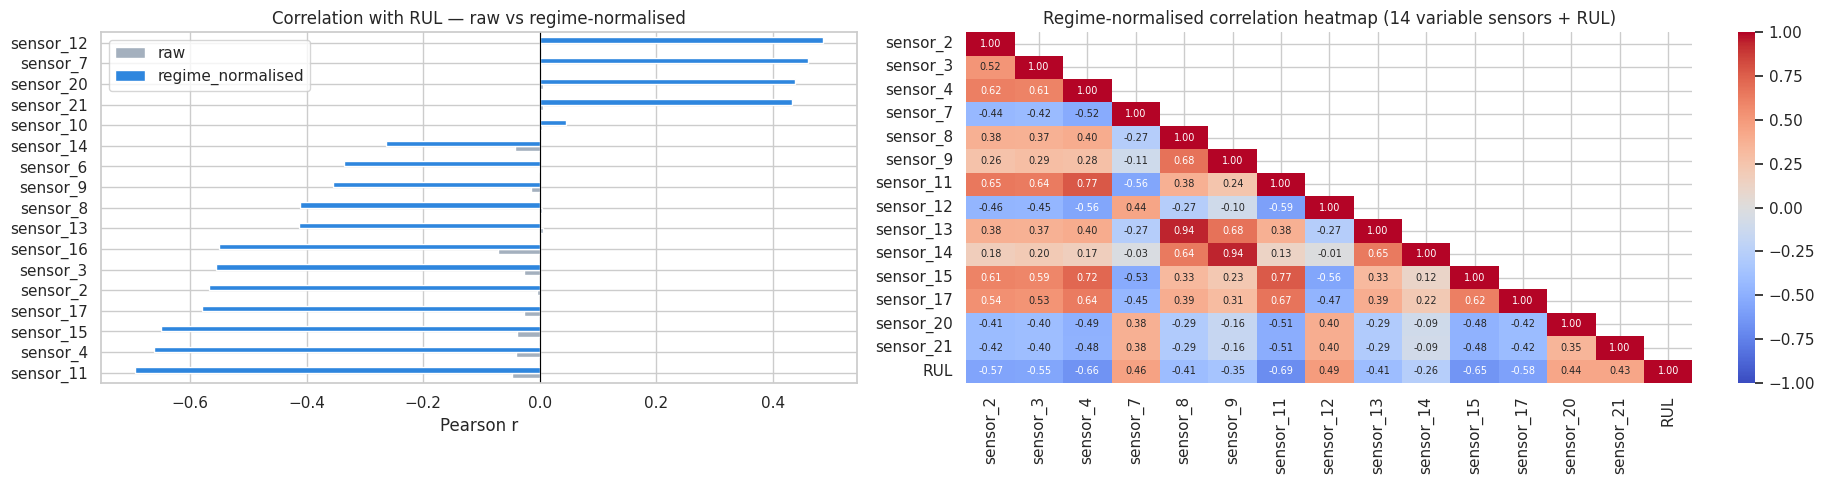

In [11]:
# Cell 10 — Correlation before and after normalisation
VARIABLE = var_df.index[var_df.flag == "variable"].tolist()
CHECK = VARIABLE + quant
corr_cmp = pd.DataFrame({
    "raw":               eda[CHECK + ["RUL"]].corr()["RUL"].drop("RUL"),
    "regime_normalised": z[CHECK + ["RUL"]].corr()["RUL"].drop("RUL"),
}).sort_values("regime_normalised")
corr_cmp.to_csv(TAB_DIR / "correlation_with_rul_raw_vs_normalised.csv")
display(corr_cmp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1.2]})
corr_cmp.plot.barh(ax=axes[0], color=["#A4B0BE", "#2E86DE"])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(title="Correlation with RUL — raw vs regime-normalised", xlabel="Pearson r")
hm = z[VARIABLE + ["RUL"]].corr()
sns.heatmap(hm, mask=np.triu(np.ones_like(hm, bool), k=1), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Regime-normalised correlation heatmap (14 variable sensors + RUL)")
fig.tight_layout(); save_fig(fig, "06_correlation_raw_vs_normalised"); plt.show()

**Interpretation — the key result of this notebook:**
- **Raw** correlations with RUL are all ≈ **0** (|r| ≤ 0.07). Looked at naively, FD002's sensors seem useless.
- After **regime normalisation** the signal reappears: `sensor_11` **−0.69**, `sensor_4` −0.66, `sensor_15` −0.65, `sensor_17` −0.58, `sensor_2` −0.57, `sensor_3` −0.56; positive side `sensor_12` +0.49, `sensor_7` +0.46, `sensor_20`/`21` ≈ +0.43.
- `sensor_16` (−0.55) and `sensor_6` (−0.34) also correlate after normalisation — consistent with the drill-down above.
- The same strongly-correlated pairs as FD001 exist (e.g. `sensor_9`/`sensor_14`).

**Implication:** per-regime normalisation is **not optional** for FD002 — it is the difference between no signal and a strong one.

## 2.9 — Sensor trends across engine cycles (normalised)

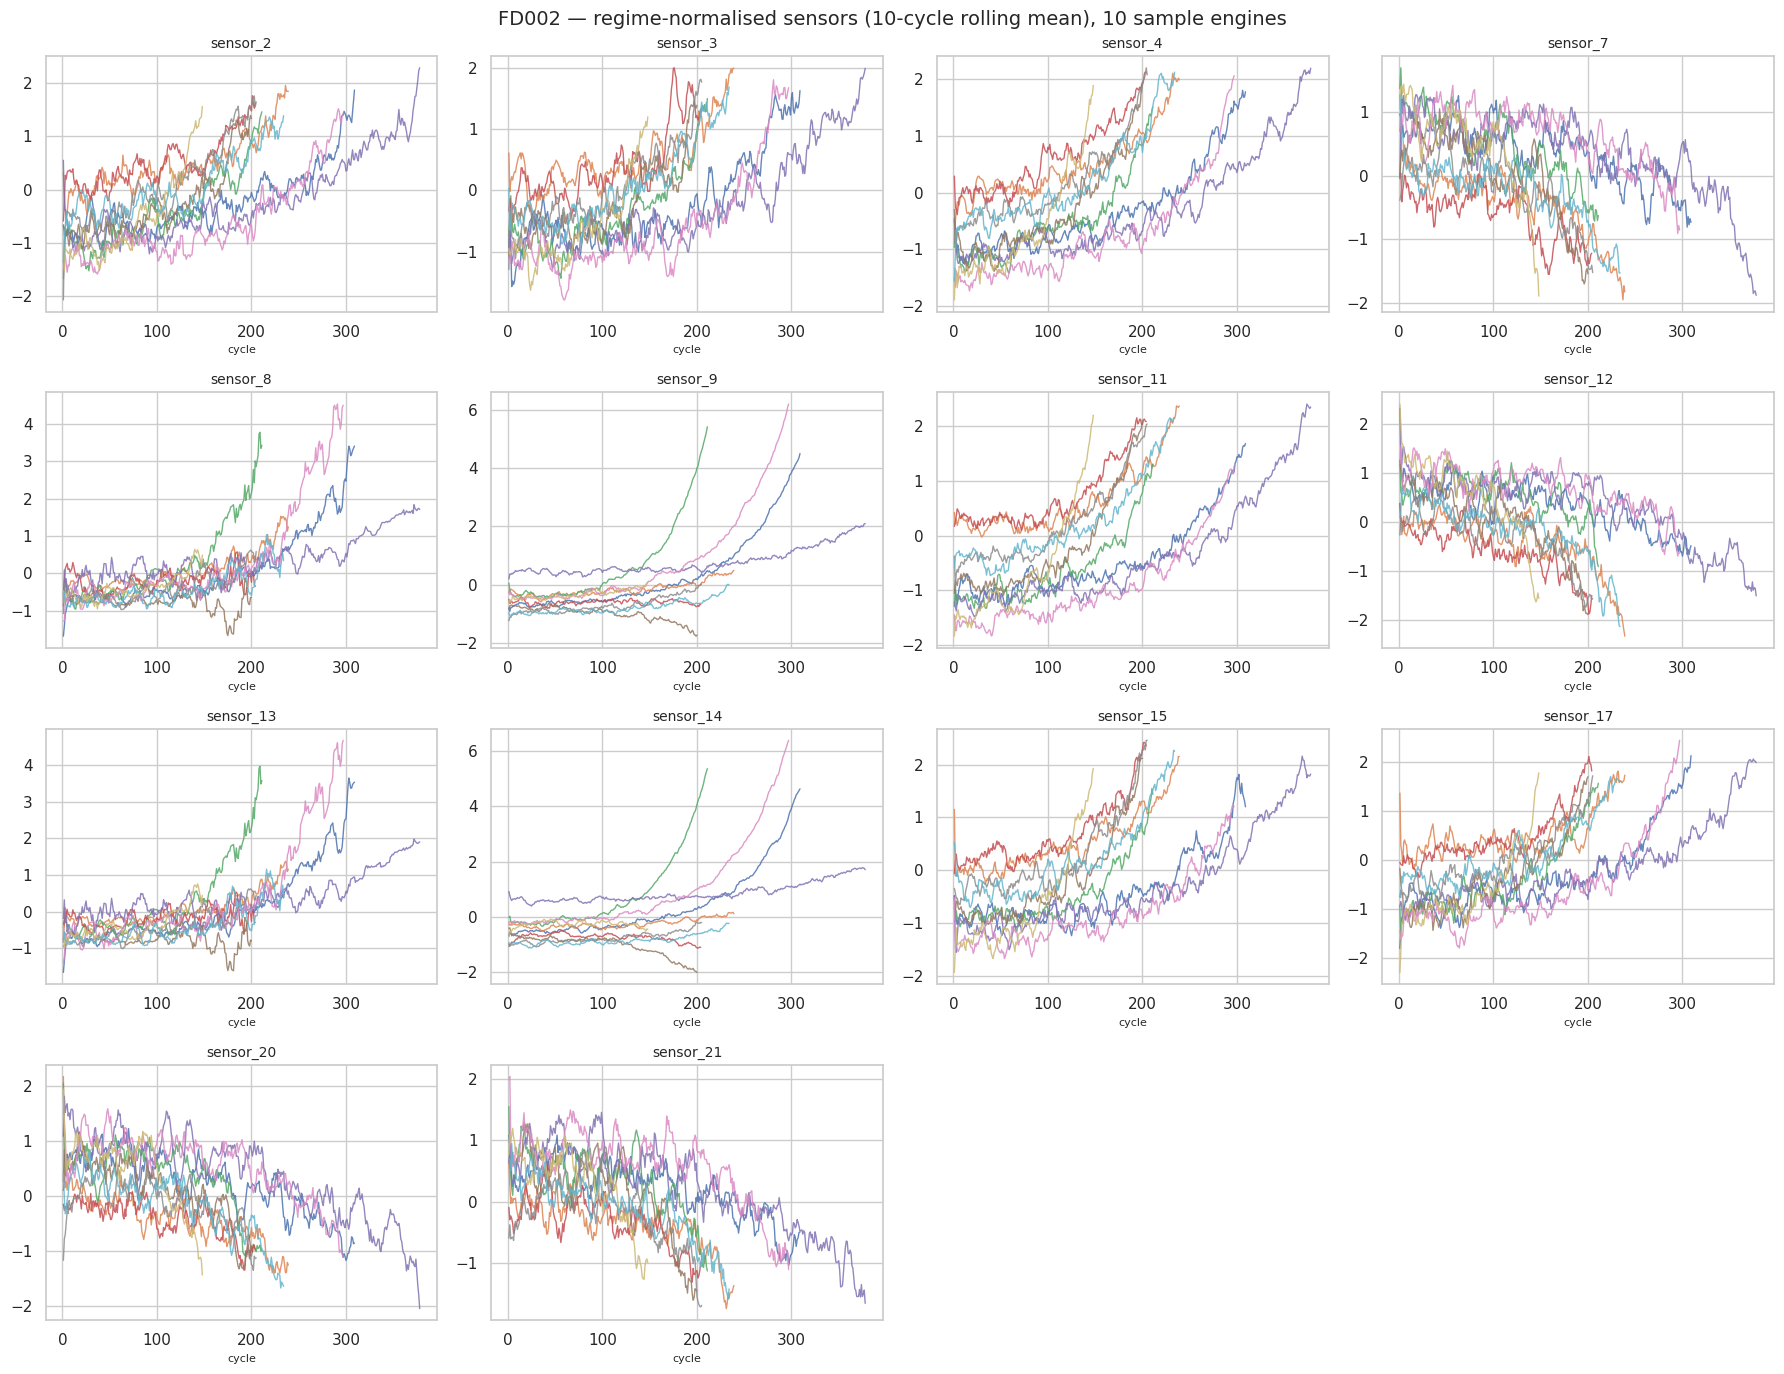

In [12]:
# Cell 11 — 10 random engines, regime-normalised, smoothed for readability
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(eda.engine_id.unique(), size=10, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, VARIABLE):
    for e in sample_ids:
        g_ = z[z.engine_id == e]
        ax.plot(g_.cycle, g_[col].rolling(10, min_periods=1).mean(), lw=1, alpha=0.85)
    ax.set_title(col, fontsize=10); ax.set_xlabel("cycle", fontsize=8)
for ax in axes.flat[len(VARIABLE):]:
    ax.axis("off")
fig.suptitle("FD002 — regime-normalised sensors (10-cycle rolling mean), 10 sample engines", fontsize=14)
fig.tight_layout(); save_fig(fig, "07_sensor_trends_sample_engines"); plt.show()

**Interpretation:** once the regime effect is removed, FD002 engines look like FD001 engines: flat early life, then a clear drift (up for sensors 2, 3, 4, 8, 11, 13, 15, 17; down for 7, 12, 20, 21) in the final stage. Readings remain noisy cycle-to-cycle, so rolling features (Phase 4) will again be useful.

## 2.10 — Degradation behaviour aligned at failure

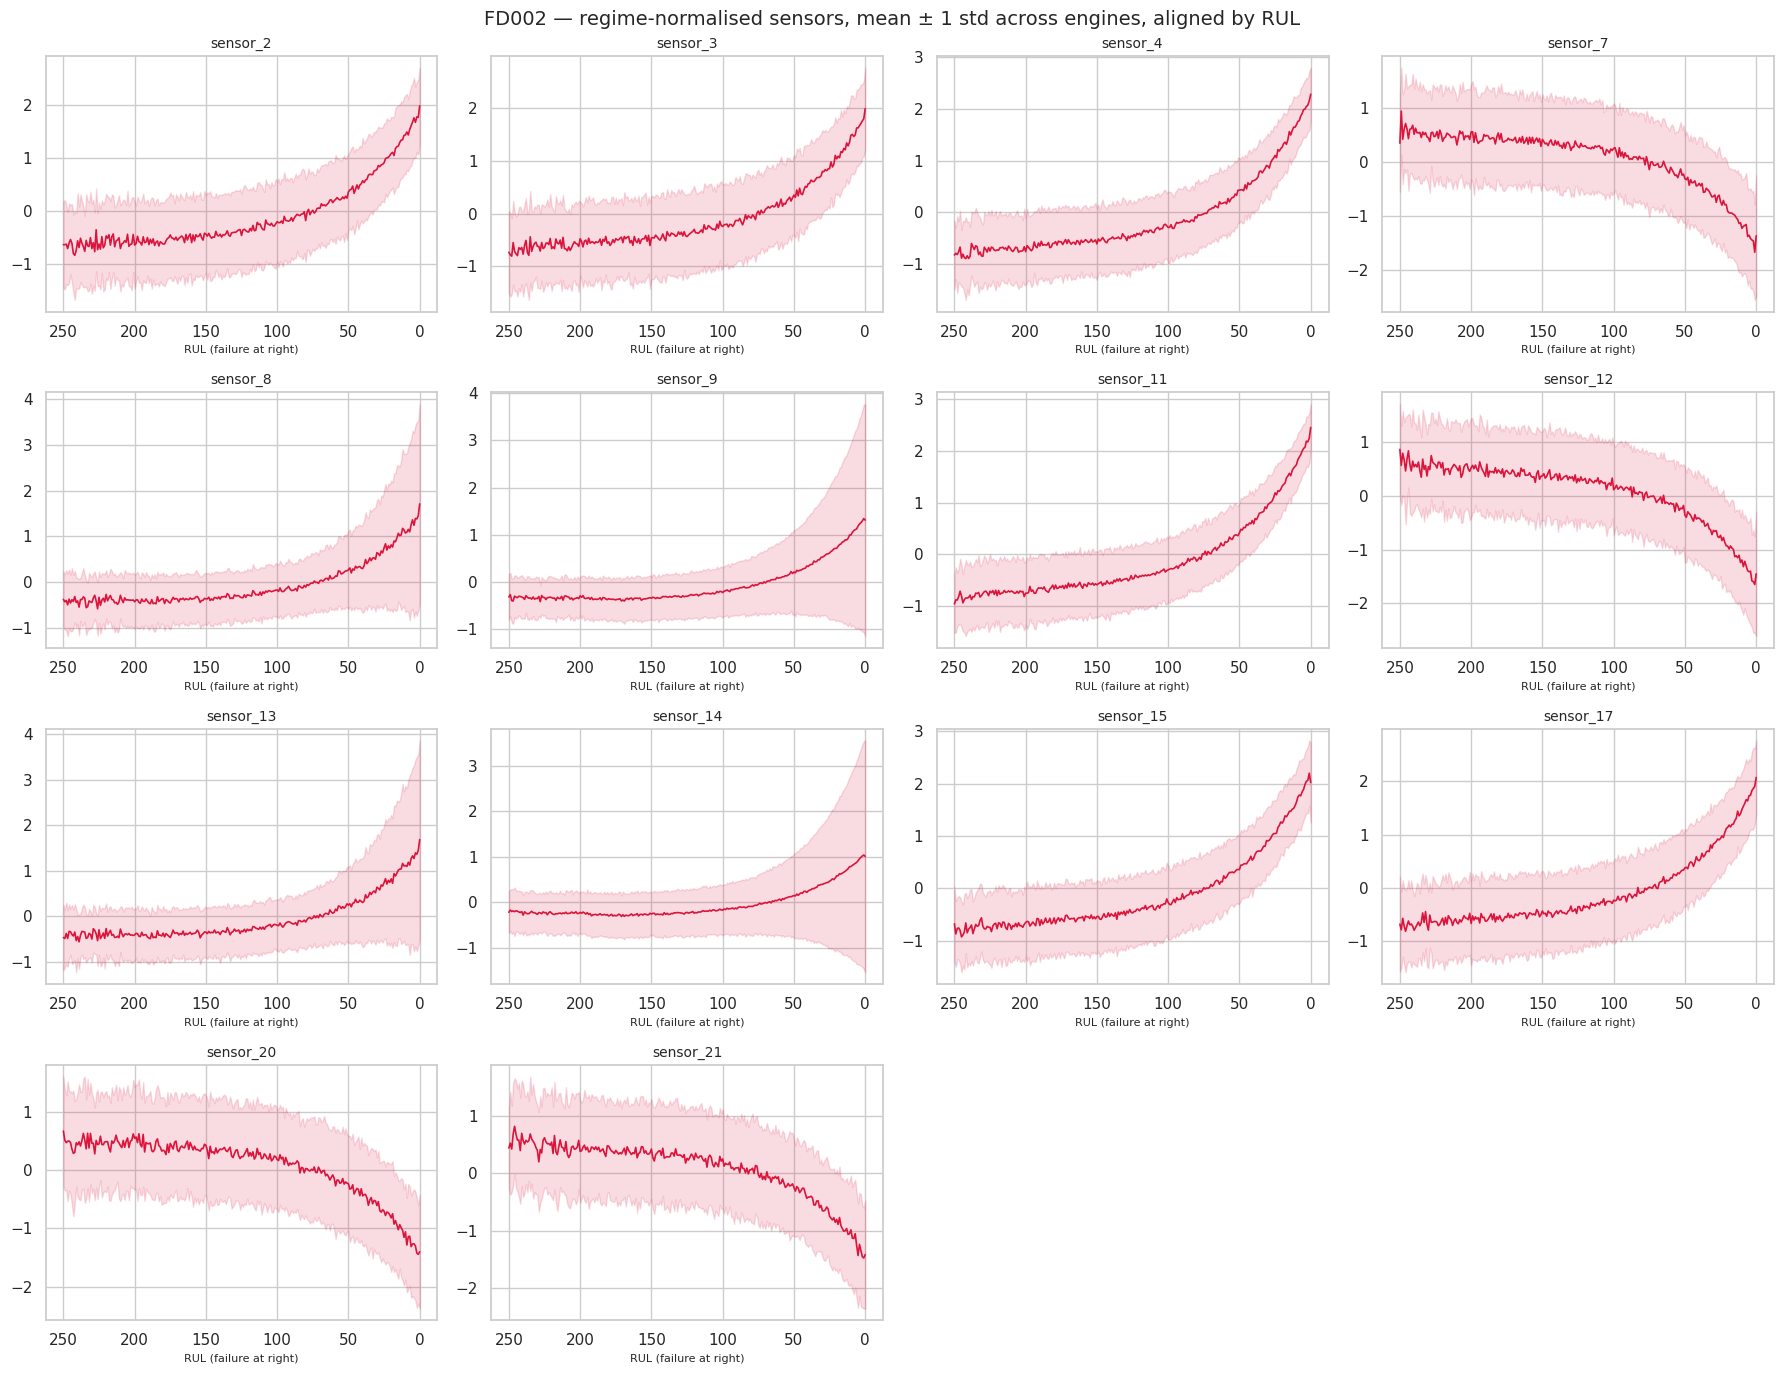

,shift_in_early_std
sensor_12,-2.10
sensor_7,-1.94
sensor_20,-1.81
sensor_21,-1.77
sensor_10,-0.18
sensor_6,1.10
sensor_14,2.38
sensor_3,2.61
sensor_2,2.64
sensor_8,2.84


In [13]:
# Cell 12 — Mean ± std across engines vs RUL, and the size of the shift
agg = z[z.RUL <= 250].groupby("RUL")[VARIABLE].agg(["mean", "std"])
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, VARIABLE):
    m, s = agg[(col, "mean")], agg[(col, "std")]
    ax.plot(m.index, m.values, color="crimson", lw=1.2)
    ax.fill_between(m.index, m - s, m + s, color="crimson", alpha=0.15)
    ax.invert_xaxis(); ax.set_title(col, fontsize=10); ax.set_xlabel("RUL (failure at right)", fontsize=8)
for ax in axes.flat[len(VARIABLE):]:
    ax.axis("off")
fig.suptitle("FD002 — regime-normalised sensors, mean ± 1 std across engines, aligned by RUL", fontsize=14)
fig.tight_layout(); save_fig(fig, "08_degradation_aligned_by_rul"); plt.show()

early, late = z[z.cycle <= 20][CHECK], z[z.RUL < 20][CHECK]
shift = ((late.mean() - early.mean()) / early.std()).rename("shift_in_early_std").sort_values()
shift.to_csv(TAB_DIR / "degradation_shift.csv"); display(shift.round(2).to_frame())

**Interpretation (actual values):**
- Same "flat, then accelerating" shape as FD001 → a capped RUL target is again worth evaluating in Phase 3.
- Shifts from early life to the last 20 cycles: `sensor_11` **+3.9**, `sensor_4` +3.6, `sensor_15` +3.4, `sensor_9` +3.3 …; falling sensors `sensor_12` −2.1, `sensor_7` −1.9, `sensor_20`/`21` ≈ −1.8.
- The noise band (shaded ±1 std) is wide relative to the trend, and regime normalisation is only an approximation of the true operating-condition effect, so FD002 is expected to be **harder** to predict than FD001 — Phase 6 will tell us by how much.
- `sensor_16` shows a large shift (+5.8) — but that comes from a single regime and a two-valued signal, so it must be validated, not trusted blindly.

## 2.11 — RUL distribution

count    53759.0
mean       108.2
std         69.2
min          0.0
25%         51.0
50%        103.0
75%        156.0
max        377.0
Name: RUL, dtype: float64
Share of rows with RUL > 100: 51.2%
Share of rows with RUL > 125: 39.1%
Share of rows with RUL > 150: 27.3%


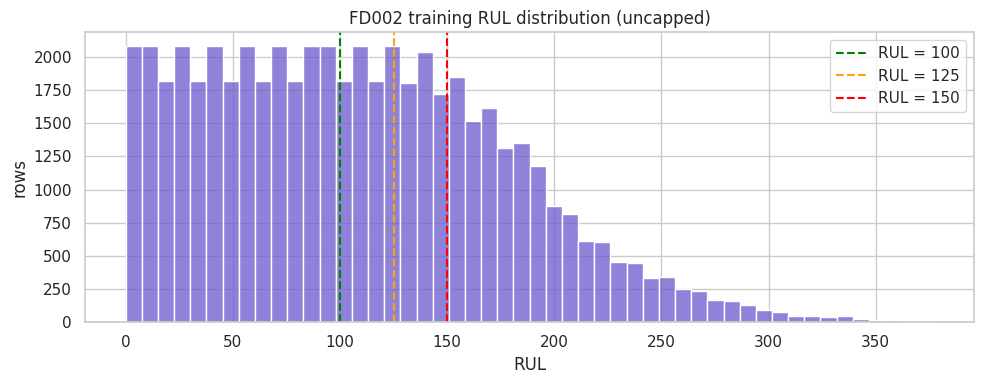

In [14]:
# Cell 13 — Training RUL (uncapped)
print(eda.RUL.describe().round(1))
for t in (100, 125, 150):
    print(f"Share of rows with RUL > {t}: {(eda.RUL > t).mean():.1%}")
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(eda.RUL, bins=50, ax=ax, color="slateblue")
for t, c in zip((100, 125, 150), ("green", "orange", "red")):
    ax.axvline(t, color=c, ls="--", label=f"RUL = {t}")
ax.set(title="FD002 training RUL distribution (uncapped)", xlabel="RUL", ylabel="rows"); ax.legend()
fig.tight_layout(); save_fig(fig, "09_rul_distribution"); plt.show()

**Interpretation:** RUL 0–377 (median 103) with **39.1%** of rows above 125 — the same staircase shape as FD001. The flat-then-steep sensor behaviour (2.10) again suggests most of those high-RUL rows are hard to distinguish, so Phase 3 will re-run the cap experiment for FD002 rather than copying FD001's 125.

## Cell 14 — Save findings for Phase 3

In [15]:
# Cell 14 — Machine-readable summary
findings = {
    "dataset": FD,
    "n_train_engines": int(train.engine_id.nunique()), "n_test_engines": int(test.engine_id.nunique()),
    "train_lifetime_min_max": [int(train_life.min()), int(train_life.max())],
    "test_observed_min": int(test_obs.min()), "test_engines_below_30_cycles": int((test_obs < 30).sum()),
    "n_regimes": int(len(regime_table)), "regime_rounding": ROUND,
    "regime_table": regime_table[["regime"] + SETTINGS + ["share"]].to_dict(orient="records"),
    "regime_change_rate": round(float(switch_rate), 3),
    "constant_within_regime": var_df.index[var_df.flag == "CONSTANT WITHIN REGIME"].tolist(),
    "quantised_within_regime": quant,
    "variable_sensors": VARIABLE,
    "corr_with_rul_raw": corr_cmp["raw"].round(4).to_dict(),
    "corr_with_rul_regime_normalised": corr_cmp["regime_normalised"].round(4).to_dict(),
    "share_rows_rul_gt_125": round(float((eda.RUL > 125).mean()), 4),
}
(TAB_DIR / "eda_findings.json").write_text(json.dumps(findings, indent=2, default=float))
print("Saved →", TAB_DIR / "eda_findings.json")

Saved → /content/drive/MyDrive/Predictive_Maintenance_RUL/reports/eda/FD002/eda_findings.json


---
## Summary — proposals for Phase 3 (FD002)
| Topic | Evidence | Proposed Phase 3 action |
|---|---|---|
| 6 operating regimes | Settings form 6 tight clusters; K-Means agrees; regime re-drawn ~82% of cycles | Identify regime from settings (rounding rule, fitted on train) |
| Regime dominates sensors | ≥ 99% of variance; raw r ≈ 0 → normalised r up to −0.69 | **Per-regime standardisation** fitted on training engines only |
| Constant within regime | sensors 1, 5, 18, 19 | Drop |
| Quantised sensors | 6 (useful-looking), 16 (one regime only), 10 (weak) | Test keep-vs-drop on validation |
| Operational settings | Only identify the regime; no wear information | Use for regime ID, not as model inputs |
| Short test histories | Min 21 cycles; 6 engines < 30 | LSTM window ≤ 21 or documented padding |
| Flat-then-steep degradation | Same as FD001 | Re-run cap experiment (none/100/125/150) |

